# 15 · The agreement rule: one valid set per row when the parents are unknown

Notebook 14 kept several candidate parent sets per machine and gave every
candidate its own set.  For planning we need **one** set per row of the
transition table, valid without knowing which candidate is right.  The
agreement rule (KWIK, "knows what it knows") does it under one declared bound:
each machine has at most `d` parents.

1. Every parent set of size `d` is a candidate.  Each candidate and each
   one-variable extension `c ∪ {v}` gets an L1 ball per row; all balls hold
   together at 90%.
2. A candidate that contains the true parents gives the same conditional as
   its extensions, so their balls overlap.  **Disjoint balls prove that a
   candidate misses a parent**, and it is discarded.
3. Each row where every survivor has data gets one ball containing all the
   survivors' balls, so it contains the truth.

The point is **coverage**.  The flat model (one row per state-action pair) has
a set only where a logger visited that pair.  The agreement rule also covers
pairs that **no logger visited**, as long as each survivor saw its own parent
values.

- **NBN API:** `nbn.structure.agreement_set`, `AgreementSet`.
- **Runtime:** under 30 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Literature: Diuk, Li & Leffler, ICML 2009 (k-meteorologists); Simão & Spaan,
IJCAI 2019 (offline, one behaviour policy); Strehl, Diuk & Littman, AAAI 2007
(the "does an extra variable change the prediction?" test).

In [1]:
import itertools
import os

import matplotlib.pyplot as plt
import torch

from nbn.structure import agreement_set
from nbn.uncertainty import parent_row_index
from nbn.utils.device import resolve_device

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})

device: cpu


## The data: the ring of notebook 14

Four machines on a one-way ring; machine `i` depends on `(m_i, m_{i-1}, rep_i)`.
Logger L repairs machines 0–1, logger R machines 2–3; both explore (a random
action) only 2% of the time, 100 episodes each.  The candidates for each machine
use any of the 8 inputs (4 statuses, 4 repair flags).  The repair flags encode
one action (do nothing, or repair one machine), so only the 16 × 5 = **80
feasible** state-action rows matter; the other flag combinations never occur,
and we count coverage on the feasible rows (`coverage_rows`).

In [2]:
N = 4
INPUTS = [f"m{i}" for i in range(N)] + [f"rep{i}" for i in range(N)]


def p_up(up, left, rep):
    """True P(up'_i = 1 | up_i, up_{i-1}, rep_i)."""
    stay = torch.where(left == 1, 0.95, 0.60)
    return torch.where(rep == 1, 0.95, torch.where(up == 1, stay, 0.05))


def collect(half, n_episodes, horizon=30, seed=0, explore=0.02):
    gen = torch.Generator().manual_seed(seed)
    up = torch.ones(n_episodes, horizon + 1, N, dtype=torch.long)
    out = {k: [] for k in INPUTS + [f"m{i}'" for i in range(N)]}
    for t in range(horizon):
        broken = (up[:, t, list(half)] == 0).float()
        pick = torch.multinomial(broken + 1e-9, 1, generator=gen).squeeze(-1)
        a = torch.where(broken.sum(-1) > 0, torch.tensor(half)[pick] + 1, 0)
        rand = torch.rand(n_episodes, generator=gen) < explore
        a = torch.where(rand, torch.randint(0, N + 1, (n_episodes,), generator=gen), a)
        rep = torch.stack([(a == i + 1).long() for i in range(N)], -1)
        up[:, t + 1] = torch.bernoulli(p_up(up[:, t], up[:, t].roll(1, -1), rep), generator=gen).long()
        for i in range(N):
            out[f"m{i}"].append(up[:, t, i])
            out[f"rep{i}"].append(rep[:, i])
            out[f"m{i}'"].append(up[:, t + 1, i])
    return {k: torch.cat(v) for k, v in out.items()}


def ring_data(n_episodes=100, seed=0):
    left, right = collect((0, 1), n_episodes, seed=2 * seed + 1), collect((2, 3), n_episodes, seed=2 * seed + 2)
    return {k: torch.cat([left[k], right[k]]).to(device) for k in left}


data = ring_data()
variables = dict.fromkeys(data, ("discrete", 2))
FEASIBLE = torch.tensor([r for r in itertools.product(range(2), repeat=len(INPUTS)) if sum(r[N:]) <= 1])
print("transitions:", data["m0"].numel(), "| feasible state-action rows:", FEASIBLE.shape[0])

transitions: 6000 | feasible state-action rows: 80


## 1. The rule on machine 0, with the bound d = 3

There are `C(8, 3) = 56` candidates.

In [3]:
res = agreement_set(variables, data, "m0'", INPUTS, max_parents=3, delta=0.1, sampling="trajectory",
                    coverage_rows=FEASIBLE)
print("candidates:", len(res.candidates), "| discarded:", len(res.discarded), "| survivors:", res.survivors)
c, why = next(iter(res.discarded.items()))
print(f"example: {c} is refuted against {why['against']} on {why['rows']} rows (gap {why['gap']:.2f})")
print("the set lives on the rows of", res.parents, "| guarantee:", res.set.guarantee)
print(f"flat model: {res.flat_visited} of {res.flat_rows} feasible rows visited (only those get a set)")
print(f"agreement rule: {res.flat_with_set} of {res.flat_rows} feasible rows get a set "
      f"({res.n_rows_gained} never visited)")

candidates: 56 | discarded: 55 | survivors: [('m0', 'm3', 'rep0')]
example: ('m0', 'm1', 'm2') is refuted against ('m0', 'm1', 'm2', 'rep0') on 4 rows (gap 0.31)
the set lives on the rows of ('m0', 'm3', 'rep0') | guarantee: pac_under_model
flat model: 68 of 80 feasible rows visited (only those get a set)
agreement rule: 80 of 80 feasible rows get a set (12 never visited)


## 2. All four machines: rows with a set

The same rule for every machine, with the budget split across the four
machines (`delta / 4` each), so the whole kernel holds at 90%.  A row of the
**joint** kernel `P(s' | s, a)` has a set when all four machines' sets cover it.

m0': survivors [('m0', 'm3', 'rep0')]
m1': survivors [('m0', 'm1', 'rep1')]
m2': survivors [('m1', 'm2', 'rep2')]
m3': survivors [('m2', 'm3', 'rep3')]
joint kernel rows: 68 of 80 visited, 80 with a set


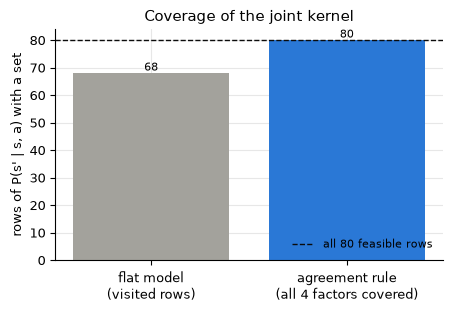

In [4]:
results = {f"m{i}'": agreement_set(variables, data, f"m{i}'", INPUTS, max_parents=3, delta=0.1 / N,
                                  sampling="trajectory", coverage_rows=FEASIBLE) for i in range(N)}
for node, r in results.items():
    print(f"{node}: survivors {r.survivors}")

covered = torch.ones(FEASIBLE.shape[0], dtype=torch.bool)
for r in results.values():
    proj = parent_row_index(FEASIBLE[:, [INPUTS.index(p) for p in r.parents]], r.parent_cards)
    covered &= ~r.set.unseen.cpu()[proj]
visited = next(iter(results.values())).flat_visited
print(f"joint kernel rows: {visited} of {FEASIBLE.shape[0]} visited, {int(covered.sum())} with a set")
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(["flat model\n(visited rows)", "agreement rule\n(all 4 factors covered)"],
              [visited, int(covered.sum())], color=[GREY, BLUE])
ax.bar_label(bars, fontsize=8)
ax.axhline(FEASIBLE.shape[0], color=INK, ls="--", lw=1, label="all 80 feasible rows")
ax.set(ylabel="rows of P(s' | s, a) with a set", title="Coverage of the joint kernel")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.show()

## 3. Are the sets right?

On every row with a set we check that the true probability is inside, for 30
fresh datasets.  The promise is 90% for all rows at once.

In [5]:
def truth_on(parents, i):
    grid = torch.cartesian_prod(*[torch.arange(2)] * len(parents)).reshape(-1, len(parents))
    col = {p: grid[:, k] for k, p in enumerate(parents)}
    p1 = p_up(col[f"m{i}"], col[f"m{(i - 1) % N}"], col[f"rep{i}"])
    return torch.stack([1 - p1, p1], -1)


n_reps, hits = 30, 0
for r in range(n_reps):
    rows = ring_data(seed=100 + r)
    ok = True
    for i in range(N):
        res_i = agreement_set(variables, rows, f"m{i}'", INPUTS, max_parents=3, delta=0.1 / N,
                              sampling="trajectory")
        s = res_i.set
        if not {f"m{i}", f"m{(i - 1) % N}", f"rep{i}"} <= set(res_i.parents):
            ok = False                              # the true parents were refuted: a miss
            continue
        truth = truth_on(res_i.parents, i).to(s.center)
        ok &= bool(s.row_contains(truth)[~s.unseen].all())
    hits += int(ok)
print(f"all rows of all machines inside their sets in {hits}/{n_reps} datasets (promise: at least 90%)")

all rows of all machines inside their sets in 30/30 datasets (promise: at least 90%)


## 4. When the bound is wrong

The true in-degree is 3.  With `d = 2` no size-2 candidate is a superset, so
the data refute them all.  The result says so and falls back to the flat model,
which is still valid but has no coverage gain.

In [6]:
low = agreement_set(variables, data, "m0'", INPUTS, max_parents=2, delta=0.1, sampling="trajectory")
print("assumption refuted:", low.assumption_refuted, "| survivors:", low.survivors)
print(f"fallback: flat model, {low.flat_with_set} of {low.flat_rows} joint input values with a set")
print("declared assumptions:", *low.assumptions, sep="\n  ")

assumption refuted: True | survivors: []
fallback: flat model, 68 of 256 joint input values with a set
declared assumptions:
  |Pa(node)| <= max_parents
  Pa(node) is a subset of inputs
  no intra-slice edges into the node; Markov observed state
  the same mechanism in every dataset (no hidden confounding)


Detection is not guaranteed: with little data a wrong candidate can survive.
The guarantee rests on the declared bound, so state it, and in doubt use a
larger `d` (more candidates, wider sets, still valid).